# Module project: build real NVP from scratch

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-2-realnvp-from-scratch.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-2-realnvp-from-scratch.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/realnvp-from-scratch` folder in the course files, to check your work.
- **Data**: No download: the three 2-D shapes are generated by `data.py` (two moons comes from scikit-learn).

In [ ]:
%pip install -q torch matplotlib scikit-learn

In the Build lesson you wrote one coupling layer by hand and checked its inverse and its determinant. In this project
you stack eight of them into a full **real NVP** normalizing flow (section 18.1), train it by exact maximum likelihood,
and put it to the test on three shapes that a single Gaussian can't describe. Then you compare it honestly with the
Gaussian mixtures of part 4.

Working in 2-D keeps everything visible: you can see the density the flow learned and every sample it draws. Figure 18.3
of the book shows real NVP on one of these shapes, the two moons.

## What you'll build

```mermaid
flowchart LR
    A[data.py<br/>two moons, ring,<br/>eight Gaussians] --> B[flow.py<br/>8 coupling layers,<br/>log_prob + sample]
    B --> C[train.py<br/>maximum likelihood,<br/>vs Gaussian + mixture]
    C --> D[samples.png<br/>real vs generated]
```

## Set up the project

```bash
mkdir realnvp-from-scratch && cd realnvp-from-scratch
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib scikit-learn
git init
```

```text
realnvp-from-scratch/
    .gitignore
    README.md
    data.py
    flow.py
    flow_eight_Gaussians.pt
    flow_ring.pt
    flow_two_moons.pt
    requirements.txt
    train.py
```

In [ ]:
%%writefile requirements.txt
torch
matplotlib
scikit-learn

Writing requirements.txt


In [ ]:
%%writefile .gitignore
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


## Step 1: three shapes

Two interleaved half-moons, a thin ring, and eight separate Gaussian clusters on a circle. Each has 5,000 training points
and 2,000 test points drawn independently.

In [ ]:
%%writefile data.py
"""Three 2-D data sets with shapes a single Gaussian can't describe. 2-D, so every result can be drawn."""
import math
import torch
from sklearn.datasets import make_moons


def two_moons(n, seed):
    x, _ = make_moons(n, noise=0.06, random_state=seed)
    return torch.tensor((x - [0.5, 0.25]) / [0.9, 0.5], dtype=torch.float32)


def ring(n, seed):
    g = torch.Generator().manual_seed(seed)
    a = torch.rand(n, generator=g) * 2 * math.pi
    r = 1.5 + 0.1 * torch.randn(n, generator=g)
    return torch.stack([r * torch.cos(a), r * torch.sin(a)], 1)


def eight_gaussians(n, seed):
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, 8, (n,), generator=g).float() * (2 * math.pi / 8)
    centres = 1.6 * torch.stack([torch.cos(k), torch.sin(k)], 1)
    return centres + 0.15 * torch.randn(n, 2, generator=g)


DATASETS = {"two moons": two_moons, "ring": ring, "eight Gaussians": eight_gaussians}


def load(name):
    """5,000 training points and 2,000 test points."""
    make = DATASETS[name]
    return make(5000, 0), make(2000, 1)

Writing data.py


## Step 2: the flow

Each `Coupling` layer is the one from the Build lesson, with a small network computing the scale `s` and shift `t`. Two
details:

- `flip` alternates which coordinate stays fixed, so after two layers both coordinates have been transformed.
- `s` passes through `tanh`, so each layer can only stretch or shrink by a factor between `e⁻¹` and `e`. Eight layers
  together can still stretch a lot, and training is much more stable.

`log_prob` runs the data through all the layers towards the latent space and adds up the log-determinants: equation 18.1
for one layer, equation 18.7 for the stack. `sample` runs the inverses in reverse order, from Gaussian noise to data.

In [ ]:
%%writefile flow.py
"""Real NVP, a coupling flow (Bishop, section 18.1), written from scratch.

The flow maps data x to latent z, one coupling layer at a time. In each layer, half of the coordinates pass through
unchanged and decide how the other half is scaled and shifted:  z_B = exp(s(x_A)) * x_B + t(x_A).
That is easy to invert, and its Jacobian is triangular, so log |det J| is just the sum of s (equation 18.14)."""
import math
import torch
from torch import nn


class Coupling(nn.Module):
    def __init__(self, flip, hidden=64):
        super().__init__()
        self.flip = flip                                  # which coordinate stays fixed in this layer
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 2))     # outputs a scale s and a shift t

    def split(self, v):
        a, b = v[:, :1], v[:, 1:]
        return (b, a) if self.flip else (a, b)

    def join(self, a, b):
        return torch.cat([b, a], 1) if self.flip else torch.cat([a, b], 1)

    def forward(self, x):                                 # data -> latent, and log |det J|
        a, b = self.split(x)
        s, t = self.net(a).chunk(2, 1)
        s = torch.tanh(s)                                 # keep the scales gentle: stabler training
        return self.join(a, b * torch.exp(s) + t), s.sum(1)

    def inverse(self, z):                                 # latent -> data, for sampling
        a, b = self.split(z)
        s, t = self.net(a).chunk(2, 1)
        return self.join(a, (b - t) * torch.exp(-torch.tanh(s)))


class RealNVP(nn.Module):
    def __init__(self, layers=8):
        super().__init__()
        self.layers = nn.ModuleList(Coupling(flip=i % 2 == 1) for i in range(layers))

    def log_prob(self, x):
        """log p(x) = log N(z | 0, I) + sum of log |det J| over the layers (equations 18.1 and 18.7)."""
        log_det = torch.zeros(len(x))
        for layer in self.layers:
            x, ld = layer(x)
            log_det = log_det + ld
        return -0.5 * (x ** 2).sum(1) - math.log(2 * math.pi) + log_det

    @torch.no_grad()
    def sample(self, n, generator=None):
        z = torch.randn(n, 2, generator=generator)
        for layer in reversed(self.layers):
            z = layer.inverse(z)
        return z

Writing flow.py


## Step 3: train and compare

Training is plain maximum likelihood (equation 18.3): minimize the negative log-likelihood of mini-batches. The
baselines come from scikit-learn: one Gaussian, and a mixture of 10 Gaussians fitted by EM (part 4).

In [ ]:
%%writefile train.py
"""Fit Real NVP to each data set by maximum likelihood, and compare its test log-likelihood with a single Gaussian
and a 10-component Gaussian mixture (scikit-learn), the density models of chapters 3 and 15."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from data import DATASETS, load
from flow import RealNVP

Path("outputs").mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
print(f"{'data set':16s} {'Gaussian':>9s} {'mixture of 10':>14s} {'Real NVP':>9s}   (test log-likelihood per point)")
for col, name in enumerate(DATASETS):
    torch.manual_seed(0)
    train, test = load(name)
    flow = RealNVP()
    opt = torch.optim.Adam(flow.parameters(), lr=2e-3)
    for step in range(3000):
        batch = train[torch.randint(0, len(train), (256,))]
        loss = -flow.log_prob(batch).mean()               # maximum likelihood (equation 18.3)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        ll_flow = flow.log_prob(test).mean().item()
    gauss = GaussianMixture(1, random_state=0).fit(train.numpy())
    gmm = GaussianMixture(10, random_state=0).fit(train.numpy())
    print(f"{name:16s} {gauss.score(test.numpy()):9.3f} {gmm.score(test.numpy()):14.3f} {ll_flow:9.3f}")

    samples = flow.sample(2000, generator=torch.Generator().manual_seed(2))
    axes[0, col].scatter(*test.T, s=2, alpha=0.4); axes[0, col].set_title(f"{name}: real test data")
    axes[1, col].scatter(*samples.T, s=2, alpha=0.4, color="C1"); axes[1, col].set_title("Real NVP samples")
    for ax in axes[:, col]:
        ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    torch.save(flow.state_dict(), f"flow_{name.replace(' ', '_')}.pt")
fig.tight_layout(); fig.savefig("outputs/samples.png", dpi=100)
print("saved outputs/samples.png")

Writing train.py


In [ ]:
!python train.py

data set          Gaussian  mixture of 10  Real NVP   (test log-likelihood per point)
two moons           -2.687         -1.358    -1.364
ring                -2.961         -1.378    -1.444
eight Gaussians     -3.097         -1.140    -1.332
saved outputs/samples.png


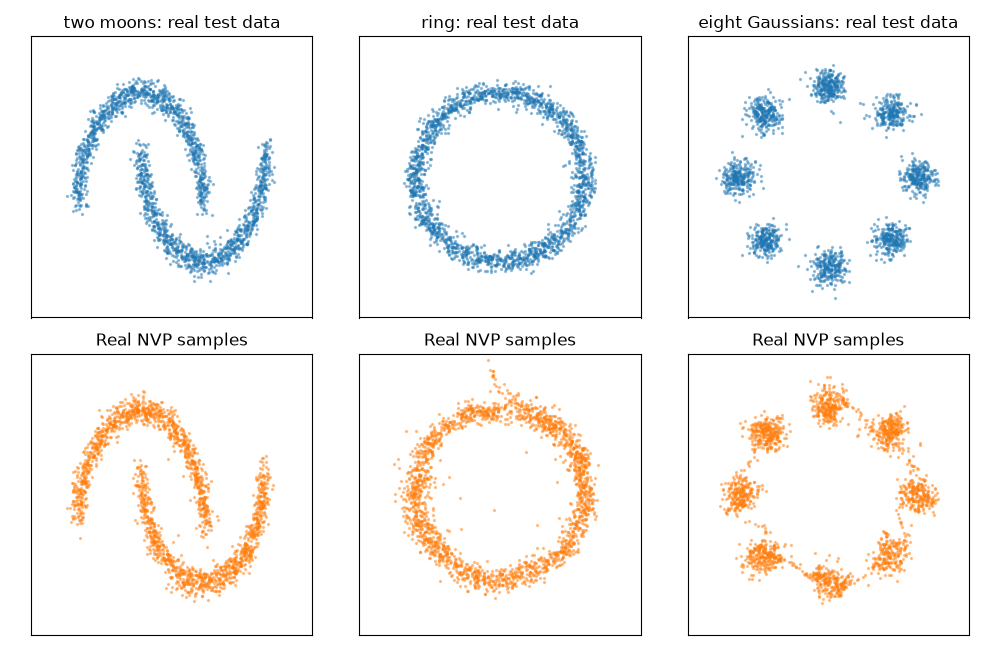

In [ ]:
from IPython.display import Image
Image('outputs/samples.png')

Read the table with the pictures:

- **The flow learns every shape**, far better than a single Gaussian (about 1.3 to 1.8 nats per point better). The samples
  follow the moons and the ring closely.
- **On two moons it ties with a 10-component mixture** (−1.364 vs −1.358).
- **On eight Gaussians the mixture wins clearly**, which is no surprise: the data literally *is* a mixture of Gaussians.
  Look at the flow's samples: thin bridges of points join neighbouring clusters, and the ring has a small stray tail. A
  flow is a smooth, invertible transformation of one Gaussian blob; it can stretch and squeeze space, but it can't tear
  it into separate pieces, so some probability always leaks between the clusters.

So why use flows at all? Because the mixture's strength doesn't scale. In two dimensions, 10 Gaussians cover any shape;
for a 64 × 64 colour image (12,288 dimensions) you'd need an astronomical number of them. Flows, built from neural
networks, scale to images, and still give an exact likelihood, which GANs never do.

## Step 4: write the README and publish

In [ ]:
%%writefile README.md
# Real NVP from scratch

A normalizing flow (real NVP, 8 affine coupling layers) written from scratch in PyTorch, trained by exact maximum
likelihood on three 2-D shapes, and compared with a single Gaussian and a 10-component Gaussian mixture.

![samples](outputs/samples.png)

## Results (test log-likelihood per point, higher is better)

| data set | Gaussian | mixture of 10 Gaussians | Real NVP |
|---|---|---|---|
| two moons | -2.687 | -1.358 | -1.364 |
| ring | -2.961 | -1.378 | -1.444 |
| eight Gaussians | -3.097 | **-1.140** | -1.332 |

Real NVP learns every shape far better than a Gaussian and matches a 10-component mixture on two moons. It's behind on
eight separate clusters: a flow is a smooth, invertible map of one Gaussian blob, so it leaves thin "bridges" of
probability between the clusters (visible in the samples).

## Run it

```bash
pip install -r requirements.txt
python train.py    # about a minute on a laptop CPU
```

## What I learned

- A flow gives an exact likelihood through the change-of-variables formula, so training is plain maximum likelihood.
- Coupling layers are invertible by construction and have a triangular Jacobian, so the log-determinant is a sum.
- A continuous invertible map can't separate disconnected clusters cleanly; mixtures can, but they don't scale to images.

Based on chapter 18 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Real NVP normalizing flow from scratch"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/realnvp-from-scratch.git
git push -u origin main
```

## Make it yours

- **Watch it learn.** Save the samples every 500 steps and make an animation of the flow bending the Gaussian into moons.
- **Depth and width.** Try 4, 8 and 16 layers. Where does the test log-likelihood stop improving? Is the eight-Gaussians
  gap ever closed?
- **Draw the density.** Evaluate `log_prob` on a grid and plot `exp(log_prob)` as a heat map. Where are the bridges?
- **A real data set.** Fit the flow to two standardized columns of a real table (for example the California housing
  locations from part 1) and compare it with the mixture again.

## On your CV

> **Real NVP from scratch** (PyTorch): normalizing flow with 8 affine coupling layers trained by exact maximum likelihood
> on 2-D benchmarks; matched a 10-component Gaussian mixture on two moons (−1.364 vs −1.358 nats/point) and analysed
> why invertible flows leak probability between disconnected clusters. github.com/YOUR-USERNAME/realnvp-from-scratch

## Check yourself

- [ ] You can write `log p(x)` for a stack of layers from equations 18.1 and 18.7.
- [ ] You can explain why `sample` runs the inverses in reverse order.
- [ ] You can explain why the flow loses on eight Gaussians and why that doesn't make flows useless.